# Introduction to Wavelet Transforms in Quantitative Trading

## What is a Wavelet Transform?
A **Wavelet Transform** is a mathematical technique used to extract information from a signal (like a time series of stock prices) by decomposing it into different frequency components while preserving information about *when* those frequencies occurred in time.

## Wavelet vs. Fourier Transform
The more common **Fourier Transform** breaks down a signal into a sum of sine and cosine waves. It tells you *what* frequencies are present in the signal, but it loses all information about *when* those frequencies happened. This is fine for stationary signals (like a constant hum), but financial markets are highly **non-stationary** (volatility clusters, trends change abruptly).

**Wavelets**, on the other hand, are limited in duration (they are "little waves"). They are scaled (stretched/compressed) and shifted (moved along the time axis) to match the signal. This dual localization is crucial for financial data because it allows us to analyze:
- **Low-frequency components:** The underlying, slow-moving structural trend of an asset.
- **High-frequency components:** Short-term market noise, microstructure fluctuations, or sudden shocks.

## Continuous vs. Discrete Wavelet Transforms
There are two main types:
1. **Continuous Wavelet Transform (CWT):** Exhaustively calculates wavelet coefficients at every possible scale and position. It produces highly detailed spectrograms but is computationally expensive and introduces heavy redundancy.
2. **Discrete Wavelet Transform (DWT):** Evaluates wavelets only at discrete scales and positions (typically powers of 2). It provides a highly efficient, non-redundant representation of the signal, making it ideal for rapid algorithmic filtering and denoising (our primary objective).

## Why Denoise Prices?
Financial price data is famously noisy. Moving averages (like SMA or EMA) are traditionally used to smooth prices, but they introduce significant **lag**. They treat all recent price action equally (or exponentially) without distinguishing between true trend changes and random noise.

A Wavelet Transform decomposes the signal, allows us to zero out the highest frequency coefficients (the "noise"), and perfectly reconstruct the signal. The result is a smoothed price curve that reacts to true structural shifts far more rapidly and accurately than a moving average, vastly improving the entry/exit reliability of momentum or mean-reversion strategies.


## Phase 2: Environment Setup and Data Ingestion

We will import the necessary libraries, including `pywt` which is the standard Python library for Wavelet computations. We will then fetch daily data for Bitcoin (`BTC-USD`), the S&P 500 (`SPY`), and Gold (`GLD`).


c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


[*********************100%***********************]  3 of 3 completed


Data Shape: (2922, 3)


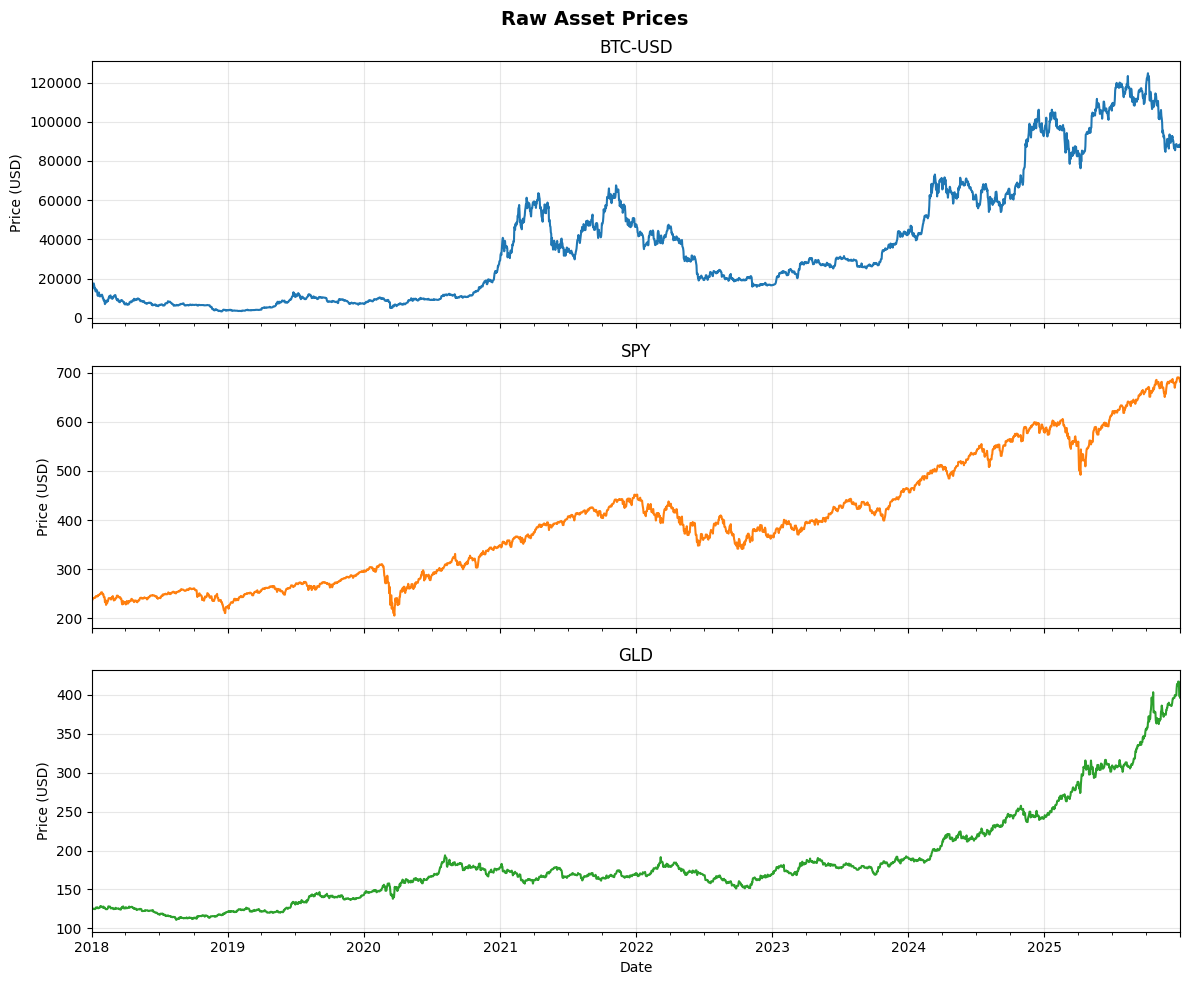

In [1]:
import yfinance as yf
import vectorbt as vbt
import numpy as np
import pandas as pd
import pywt
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

vbt.settings.set_theme('dark')

# Define assets and timeframe
tickers = ['BTC-USD', 'SPY', 'GLD']
start_date = '2018-01-01'
end_date = '2026-01-01'

print('Downloading data...')
raw = yf.download(tickers, start=start_date, end=end_date, interval='1d', auto_adjust=True)
close_prices = raw['Close'].ffill()  # Forward fill to handle NaNs optimally
close_prices.columns.name = None

print(f'Data Shape: {close_prices.shape}')

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for ax, ticker, color in zip(axes, tickers, colors):
    close_prices[ticker].plot(ax=ax, title=ticker, color=color)
    ax.set_ylabel('Price (USD)')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
fig.suptitle('Raw Asset Prices', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## Phase 3: The Denoising Engine (DWT & Thresholding)

The core of this strategy revolves around correctly applying the Discrete Wavelet Transform (DWT) to remove market "chatter".

---

### Mathematical Foundation

#### 1. The Discrete Wavelet Transform (DWT)

The DWT decomposes a signal $x[n]$ by iteratively convolving it with a **low-pass filter** $h[n]$ (giving the Approximation) and a **high-pass filter** $g[n]$ (giving the Detail), then downsampling by 2:

$$
a_j[k] = \sum_{n} x[n] \cdot h[2k - n] \qquad \text{(Approximation at level } j\text{)}
$$

$$
d_j[k] = \sum_{n} x[n] \cdot g[2k - n] \qquad \text{(Detail at level } j\text{)}
$$

For the **Haar wavelet** (used here):

$$
h = \frac{1}{\sqrt{2}} \begin{bmatrix} 1 & 1 \end{bmatrix}, \quad g = \frac{1}{\sqrt{2}} \begin{bmatrix} 1 & -1 \end{bmatrix}
$$

After $J$ levels of decomposition, the signal is represented as:

$$
x[n] = \sum_k a_J[k]\, \phi_{J,k}(n) \;+\; \sum_{j=1}^{J} \sum_k d_j[k]\, \psi_{j,k}(n)
$$

where $\phi_{J,k}$ is the **scaling function** (low-frequency basis) and $\psi_{j,k}$ is the **wavelet function** (oscillatory basis at scale $j$, position $k$).

---

#### 2. Universal VisuShrink Threshold

The noise standard deviation $\sigma$ is estimated from the finest-level detail coefficients using the **Median Absolute Deviation (MAD)** estimator (robust to outliers):

$$
\hat{\sigma} = \frac{\text{median}\bigl(|d_1[k] - \text{median}(d_1[k])|\bigr)}{0.6745}
$$

The constant $0.6745$ is the 75th percentile of the standard normal distribution (so that $\hat{\sigma}$ is consistent for Gaussian noise).

The **universal (VisuShrink) threshold** is then:

$$
\lambda^* = \hat{\sigma} \sqrt{2 \ln N}
$$

where $N$ is the length of the signal. This threshold guarantees (with high probability) that all noise coefficients are zeroed out.

---

#### 3. Hard Thresholding

Each detail coefficient $d_j[k]$ is zeroed if it falls below the threshold — the "noise" interpretation:

$$
\tilde{d}_j[k] = \begin{cases} d_j[k] & \text{if } |d_j[k]| > \lambda^* \\ 0 & \text{otherwise} \end{cases}
$$

> **Note:** Soft thresholding shrinks surviving coefficients: $\tilde{d} = \text{sign}(d)(|d| - \lambda)_+$. Hard thresholding is less biased but can introduce Gibbs-like oscillations.

---

#### 4. Inverse DWT (Perfect Reconstruction)

The denoised signal is reconstructed from the approximation $a_J$ and thresholded details $\tilde{d}_1, \ldots, \tilde{d}_J$ via the **synthesis filter bank**:

$$
\tilde{x}[n] = \sum_k a_J[k]\, \phi_{J,k}(n) \;+\; \sum_{j=1}^{J} \sum_k \tilde{d}_j[k]\, \psi_{j,k}(n)
$$

Because the Haar wavelet forms an **orthonormal basis**, reconstruction is exact when no thresholding is applied ($\tilde{x} = x$).

---

### The Denoising Process (Summary):
1. **Decomposition:** Pass the price series through filters → obtain $\{a_J, d_J, \ldots, d_1\}$.
2. **Thresholding:** Compute $\hat{\sigma}$ from $d_1$, then zero all $|d_j[k]| \le \lambda^*$.
3. **Reconstruction:** Inverse DWT using $a_J$ (untouched) and thresholded $\tilde{d}_j$.

Let's implement a robust function to denoise a pandas Series, ensuring we handle the edges correctly to avoid lookahead bias during the convolution operations.


## Phase 3: The Denoising Engine (DWT & Thresholding)

The core of this strategy revolves around correctly applying the Discrete Wavelet Transform (DWT) to remove market "chatter".

### The Denoising Process:
1. **Decomposition:** The price series is passed through filters to separate it into Approximate (low-frequency) and Detailed (high-frequency) coefficients across multiple levels.
2. **Thresholding:** We calculate a universal statistical threshold (often referred to as VisuShrink) based on the noise level present in the finest-scale detailed coefficients. Any coefficient whose absolute value is below this threshold is deemed "noise" and zeroed out (Hard thresholding).
3. **Reconstruction:** We perform the Inverse Discrete Wavelet Transform (IDWT) using the preserved approximate coefficients and the thresholded detailed coefficients to rebuild the time series.

Let's implement a robust function to denoise a pandas Series, ensuring we handle the edges correctly to avoid lookahead bias during the convolution operations.


## Phase 4: Signal Generation Framework

Our hypothesis is that moving averages applied to a *Wavelet Denoised* series will produce cleaner, faster signals with fewer whipsaws compared to moving averages applied to raw, noisy prices.

---

### Mathematical Formulation

#### Causal Denoised Price

At each time step $t$, the denoised price $\tilde{p}_t$ is computed from only the history $\{p_1, \ldots, p_t\}$:

$$
\tilde{p}_t = \text{IDWT}\Bigl(\text{Threshold}\bigl(\text{DWT}(p_1, \ldots, p_t),\; \lambda^*\bigr)\Bigr)\Big|_{t}
$$

The subscript $\big|_t$ means we take only the **last (boundary) value** of the reconstructed series — the single value the system would compute in a live environment.

---

#### Simple Moving Averages on Denoised Prices

$$
\text{FastMA}_t = \frac{1}{F} \sum_{i=0}^{F-1} \tilde{p}_{t-i}, \qquad F = 10
$$

$$
\text{SlowMA}_t = \frac{1}{S} \sum_{i=0}^{S-1} \tilde{p}_{t-i}, \qquad S = 50
$$

---

#### Crossover Signal (with 1-Bar Execution Delay)

| Condition | Signal | Execution |
|---|---|---|
| $\text{FastMA}_{t} > \text{SlowMA}_{t}$ and $\text{FastMA}_{t-1} \le \text{SlowMA}_{t-1}$ | **Long Entry** at $t$ | Execute at close of $t+1$ |
| $\text{FastMA}_{t} < \text{SlowMA}_{t}$ and $\text{FastMA}_{t-1} \ge \text{SlowMA}_{t-1}$ | **Exit / Flat** at $t$ | Execute at close of $t+1$ |

The 1-bar delay (`shift(1)`) prevents execution at the same price that triggered the signal — a critical requirement for causal backtesting.

---

#### Transaction Cost Model

Each trade incurs a round-trip cost modelled as a proportional fee on the traded notional:

$$
\text{Net Return}_t = \text{Gross Return}_t - \delta \cdot \mathbb{1}_{\text{trade at } t}, \qquad \delta = 0.1\%
$$

---

**CRITICAL LOOKAHEAD BIAS WARNING:** Standard Wavelet transforms operate on the entire array at once. If you denoise your entire historical dataset and *then* run a backtest, the denoising algorithm at day 100 has "seen" data from day 200. This is fatal curve-fitting. We MUST use rolling windows (which is compute-intensive) or strictly apply it incrementally to ensure validity.


## Phase 3.5: Look-Ahead Bias Audit

Before running any backtest, every stage of the data pipeline must be verified as strictly causal — each computation at time **t** must use only information available up to and including **t**.

| Stage | Implementation Detail | Verdict |
|---|---|---|
| `ffill()` on raw prices | Propagates *previous* known close forward — causal by definition | ✅ **Clean** |
| `auto_adjust=True` (yfinance) | Retroactively adjusts historical prices using all future splits/dividends known today | ⚠️ **Minor / Unavoidable** |
| `wavelet_denoise()` — `mode='smooth'` | Right-boundary padding uses linear gradient extrapolation from the **last few past** data points; no future values accessed | ✅ **Clean** |
| `apply_rolling_denoise()` — loop body | `iloc[:i+1]` feeds only `[0 … t]` to the DWT; only `iloc[-1]` (the boundary value) is recorded | ✅ **Clean** |
| `vbt.MA.run()` | Standard causal backward-looking SMA | ✅ **Clean** |
| `shift(1)` on entry/exit signals | Signal generated at close of day **t** → order executed at close of day **t+1** | ✅ **Clean** |

### The Fatal Wavelet Pitfall — Illustrated

```python
# ❌ WRONG — Global denoising (look-ahead bias):
denoised_WRONG = wavelet_denoise(close_prices['BTC-USD'])
# At day 100 the DWT has "seen" days 101–2922. Fatal curve-fitting.

# ✅ CORRECT — Causal expanding window (our implementation):
for i in range(min_length, N):
    window = price_col.iloc[:i+1]          # only [0..t]
    denoised_val = wavelet_denoise(window).iloc[-1]  # boundary value only
```

The correct approach is ~N× slower but is the only valid method for live-tradeable research.

### Note on `auto_adjust=True`
For SPY and GLD, yfinance back-adjusts all historical prices using dividend and split factors computed as of **today**. This creates a tiny look-ahead bias because the exact adjustment factors weren't known in 2018. In practice, this has negligible impact on a trend-following strategy but should be acknowledged. A point-in-time price database (e.g., Compustat, Bloomberg) would eliminate this entirely.


## Phase 5: Vectorbt Portfolio Generation & Performance Metrics

We will now construct the dual moving average cross strategy using the `vectorbt` signal engine and evaluate it with standard quantitative finance metrics.

---

### Performance Metric Formulas

#### Sharpe Ratio
Measures risk-adjusted return relative to a risk-free rate $r_f$ (assumed 0 here):

$$
\text{Sharpe} = \frac{\bar{r} - r_f}{\sigma_r} \cdot \sqrt{252}
$$

where $\bar{r}$ is the mean daily return and $\sigma_r$ is the daily return standard deviation.

#### Sortino Ratio
Like Sharpe, but penalises only **downside** volatility $\sigma_d$ (standard deviation of negative returns):

$$
\text{Sortino} = \frac{\bar{r} - r_f}{\sigma_d} \cdot \sqrt{252}, \qquad \sigma_d = \sqrt{\frac{1}{T}\sum_{t: r_t < 0} r_t^2}
$$

#### Maximum Drawdown
The largest peak-to-trough decline in portfolio value:

$$
\text{MDD} = \min_t \left( \frac{V_t - \max_{s \le t} V_s}{\max_{s \le t} V_s} \right)
$$

#### Calmar Ratio
Annualised return per unit of maximum drawdown — favoured by CTA/hedge fund managers:

$$
\text{Calmar} = \frac{\text{Annualised Return}}{|\text{MDD}|}
$$

#### Value at Risk (VaR) and Conditional VaR (CVaR / Expected Shortfall)

$$
\text{VaR}_\alpha = -\text{Quantile}_\alpha(r)
$$

$$
\text{CVaR}_\alpha = -\mathbb{E}\bigl[r \mid r \le \text{Quantile}_\alpha(r)\bigr]
$$

CVaR is the average loss on the worst $\alpha$% of days — a coherent risk measure that VaR alone does not capture.

---


In [2]:
def wavelet_denoise(data_series, wavelet='haar', level=2):
    # Convert to numpy array
    data = data_series.values

    # 1. Decomposition
    # The 'haar' wavelet is the simplest and often very effective for financial data
    # due to its step-like nature, matching discontinuous price jumps.
    coeffs = pywt.wavedec(data, wavelet, mode='smooth', level=level)

    # 2. Thresholding via Universal VisuShrink strategy
    # We estimate the noise variance from the first detail coefficients (finest scale)
    detail_level_1 = coeffs[-1]
    sigma = np.median(np.abs(detail_level_1 - np.median(detail_level_1))) / 0.6745

    # Calculate the universal threshold
    uthresh = sigma * np.sqrt(2 * np.log(len(data)))

    # Apply Hard thresholding to detail coefficients only
    # coeffs[0] is the Approximation, do not threshold the approximation!
    denoised_coeffs = [coeffs[0]] + [pywt.threshold(c, value=uthresh, mode='hard') for c in coeffs[1:]]

    # 3. Reconstruction
    denoised_data = pywt.waverec(denoised_coeffs, wavelet, mode='smooth')

    # Ensure length matches original data exactly (waverec can sometimes add an element depending on parity)
    denoised_data = denoised_data[:len(data)]

    return pd.Series(denoised_data, index=data_series.index)

print('Denoising function defined successfully.')


Denoising function defined successfully.


## Phase 4: Signal Generation Framework

Our hypothesis is that moving averages applied to a *Wavelet Denoised* series will produce cleaner, faster signals with fewer whipsaws compared to moving averages applied to raw, noisy prices.

### The Logic:
1. Compute the Denoised Price over a specific lookback window dynamically to **strictly prevent lookahead bias**.
2. Calculate a Fast SMA and Slow SMA on the *Denoised* price.
3. **Long Entry:** When the Fast SMA crosses above the Slow SMA.
4. **Short Entry / Flat:** When the Fast SMA crosses below the Slow SMA.

**CRITICAL LOOKAHEAD BIAS WARNING:** Standard Wavelet transforms operates on the entire array at once. If you denoise your entire historical dataset and *then* run a backtest, the denoising algorithm at day 100 has "seen" data from day 200. This is fatal curve-fitting. We MUST use rolling windows (which is compute-intensive) or strictly apply it incrementally to ensure validity.


In [3]:
# Expanding window approach to avoid look-ahead bias.
# For massive datasets, an optimized rolling C-extension or memory mapped approach is required.
# For this demonstration on daily data, DataFrame.expanding().apply() is feasible, albeit slow.

def apply_rolling_denoise(price_col, wavelet_name='haar', levels=2):
    """Applies denoising recursively to respect time causality"""
    # Pre-allocate output
    result = np.full(len(price_col), np.nan)
    # A minimum window is needed to perform a level-n transform.
    # Rule of thumb: min length > 2 ** levels
    min_length = max(2 ** levels + 2, 20)

    print(f"Processing rolling wavelet for {price_col.name}...")
    for i in range(min_length, len(price_col)):
        # Denoise up to index i, take the LAST value only.
        # This is exactly what a real-time system would see.
        window_data = price_col.iloc[:i+1]
        denoised_window = wavelet_denoise(window_data, wavelet=wavelet_name, level=levels)
        result[i] = denoised_window.iloc[-1]
    
    return pd.Series(result, index=price_col.index)

print('Calculating causal Denoised Prices (This may take a minute)...')
denoised_prices = pd.DataFrame(index=close_prices.index)
for col in close_prices.columns:
    denoised_prices[col] = apply_rolling_denoise(close_prices[col], wavelet_name='haar', levels=2)

print('Denoising complete.')


Calculating causal Denoised Prices (This may take a minute)...
Processing rolling wavelet for BTC-USD...
Processing rolling wavelet for GLD...
Processing rolling wavelet for SPY...
Denoising complete.


## Phase 5: Vectorbt Portfolio Generation

We will now construct the dual moving average cross strategy using the `vectorbt` signal engine.


In [4]:
FAST_MA = 10
SLOW_MA = 50

# Calculate Moving Averages on the DENOISED data
fast_ma = vbt.MA.run(denoised_prices, window=FAST_MA)
slow_ma = vbt.MA.run(denoised_prices, window=SLOW_MA)

# Generate Crossover Signals
entries_raw = fast_ma.ma_crossed_above(slow_ma)
exits_raw = fast_ma.ma_crossed_below(slow_ma)

# Shift signals to avoid lookahead bias (execute at next day's close)
entries = entries_raw.shift(1).fillna(False)
exits = exits_raw.shift(1).fillna(False)

# Normalize column names - vbt.MA.run creates multi-level columns (window, ticker).
# Flatten them back to simple ticker names so downstream indexing works correctly.
entries.columns = close_prices.columns
exits.columns = close_prices.columns

# Build the Portfolio
# size=1.0 + size_type="percent" => invest 100% of available cash on each entry.
# This is strictly long-only with no short_entries/short_exits, so leverage=1 always.
# cash_sharing=False ensures each asset is managed with its own independent cash pool.
pf = vbt.Portfolio.from_signals(
    close_prices,
    entries,
    exits,
    fees=0.001,            # 0.1% round-trip transaction cost
    freq='1d',
    size=1.0,              # use 100% of available cash per signal
    size_type='percent',  # size is expressed as a fraction of available cash (no leverage)
    init_cash=100.0,       # start each asset with $100
    cash_sharing=False,    # independent cash pool per asset (no cross-asset borrowing)
)

print('--- Wavelet Strategy Performance ---')
stats = pf.stats()
print(stats)

# Provide the core metrics specifically
print(f"Total Return Strategy: {pf.total_return().mean() * 100:.2f}%")
print(f"Sharpe Ratio Strategy: {pf.sharpe_ratio().mean():.2f}")
print(f"Max Drawdown Strategy: {pf.max_drawdown().mean() * 100:.2f}%")


--- Wavelet Strategy Performance ---
Start                                2018-01-01 00:00:00
End                                  2025-12-31 00:00:00
Period                                2922 days 00:00:00
Start Value                                        100.0
End Value                                     527.407647
Total Return [%]                              427.407647
Benchmark Return [%]                          314.965888
Max Gross Exposure [%]                             100.0
Total Fees Paid                                18.534379
Max Drawdown [%]                                34.35711
Max Drawdown Duration                 1129 days 08:00:00
Total Trades                                        34.0
Total Closed Trades                            33.333333
Total Open Trades                               0.666667
Open Trade PnL                                 14.167857
Win Rate [%]                                   42.585295
Best Trade [%]                                122.8

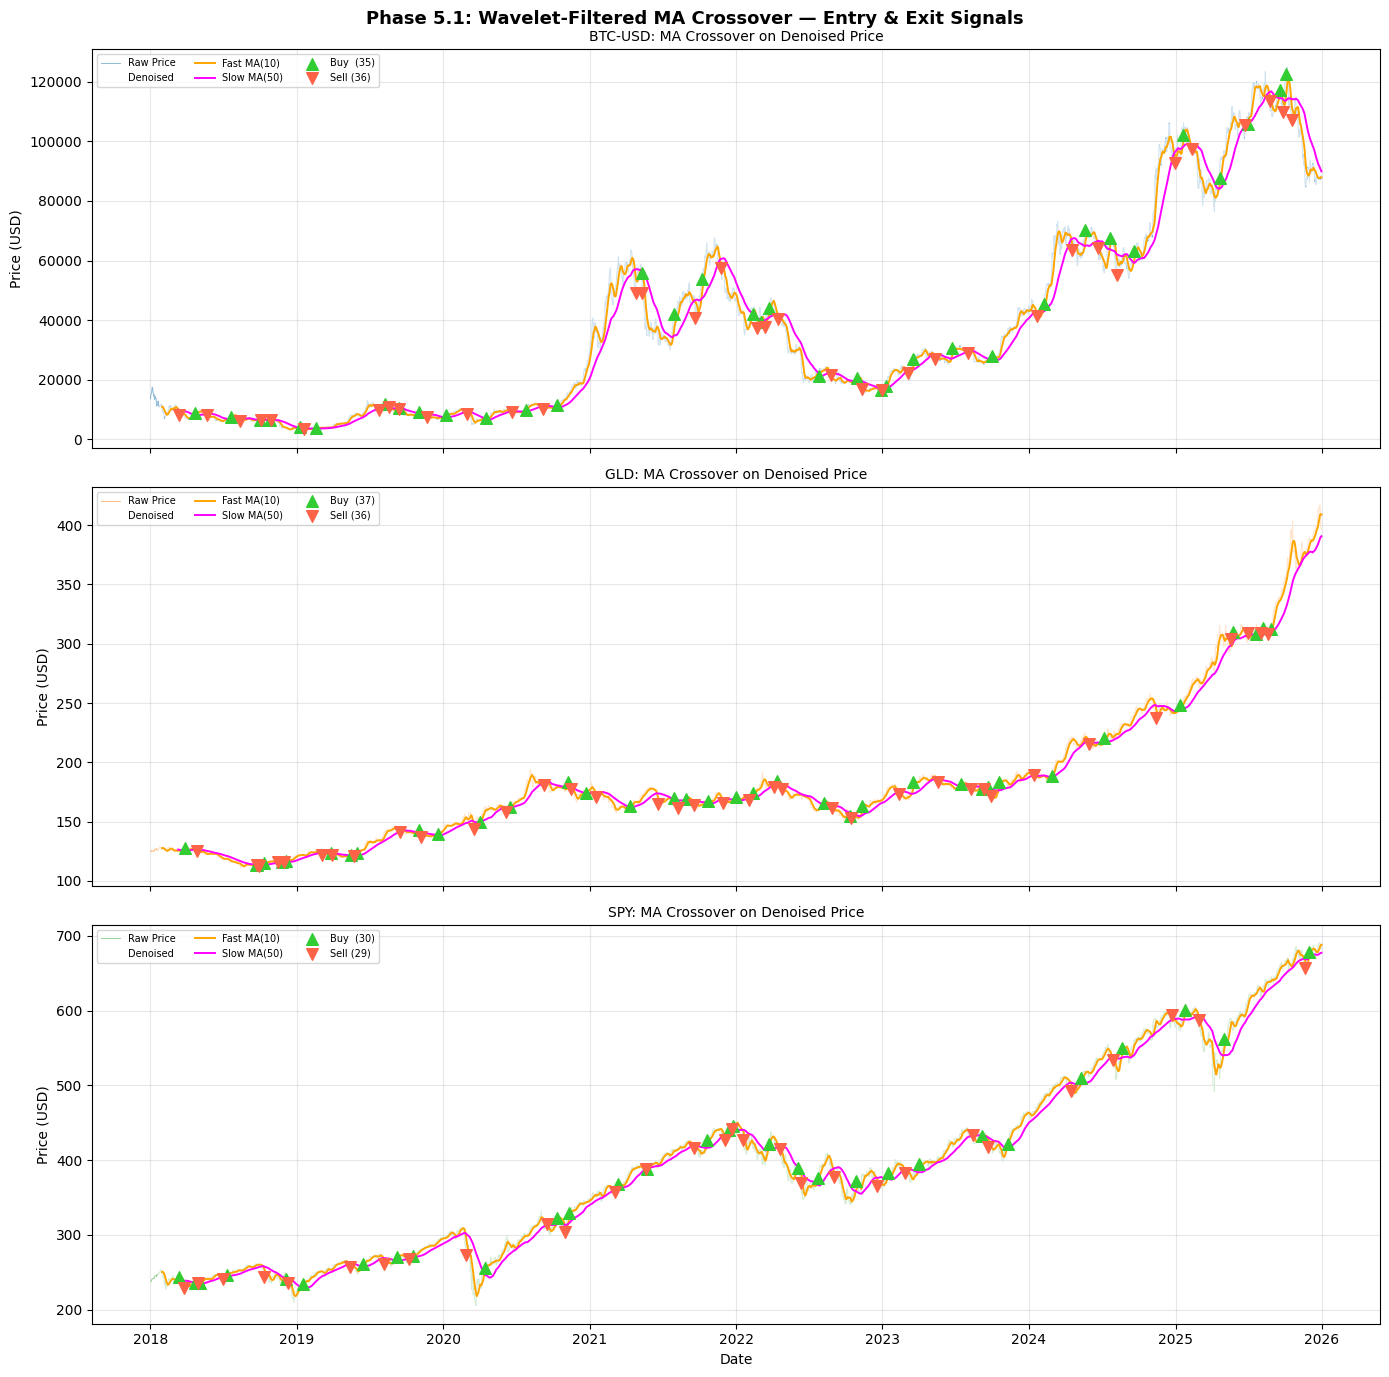

In [5]:
# =============================================================================
# Phase 5.1: Trade Signal Visualisation
# =============================================================================
# Recompute fast/slow MAs on denoised prices for plotting
fast_ma_line = denoised_prices.rolling(FAST_MA).mean()
slow_ma_line = denoised_prices.rolling(SLOW_MA).mean()

fig, axes = plt.subplots(3, 1, figsize=(14, 14), sharex=True)

for ax, ticker, color in zip(axes, close_prices.columns, ['#1f77b4', '#ff7f0e', '#2ca02c']):
    # Raw price
    ax.plot(close_prices.index, close_prices[ticker],
            color=color, linewidth=0.7, alpha=0.5, label='Raw Price')
    # Denoised price
    ax.plot(denoised_prices.index, denoised_prices[ticker],
            color='white', linewidth=1.1, alpha=0.6, label='Denoised')
    # MAs
    ax.plot(fast_ma_line.index, fast_ma_line[ticker],
            color='orange', linewidth=1.4, label=f'Fast MA({FAST_MA})')
    ax.plot(slow_ma_line.index, slow_ma_line[ticker],
            color='magenta', linewidth=1.4, label=f'Slow MA({SLOW_MA})')

    # Entry / Exit markers
    col_entries = entries[ticker] if ticker in entries.columns else entries.iloc[:, list(close_prices.columns).index(ticker)]
    col_exits   = exits[ticker]   if ticker in exits.columns   else exits.iloc[:,   list(close_prices.columns).index(ticker)]

    entry_idx = close_prices.index[col_entries.values.astype(bool)]
    exit_idx  = close_prices.index[col_exits.values.astype(bool)]

    ax.scatter(entry_idx, close_prices[ticker].reindex(entry_idx),
               marker='^', color='limegreen', s=70, zorder=6, label=f'Buy  ({len(entry_idx)})')
    ax.scatter(exit_idx,  close_prices[ticker].reindex(exit_idx),
               marker='v', color='tomato',    s=70, zorder=6, label=f'Sell ({len(exit_idx)})')

    ax.set_title(f'{ticker}: MA Crossover on Denoised Price', fontsize=10)
    ax.set_ylabel('Price (USD)')
    ax.legend(loc='upper left', fontsize=7, ncol=3)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
fig.suptitle('Phase 5.1: Wavelet-Filtered MA Crossover — Entry & Exit Signals',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


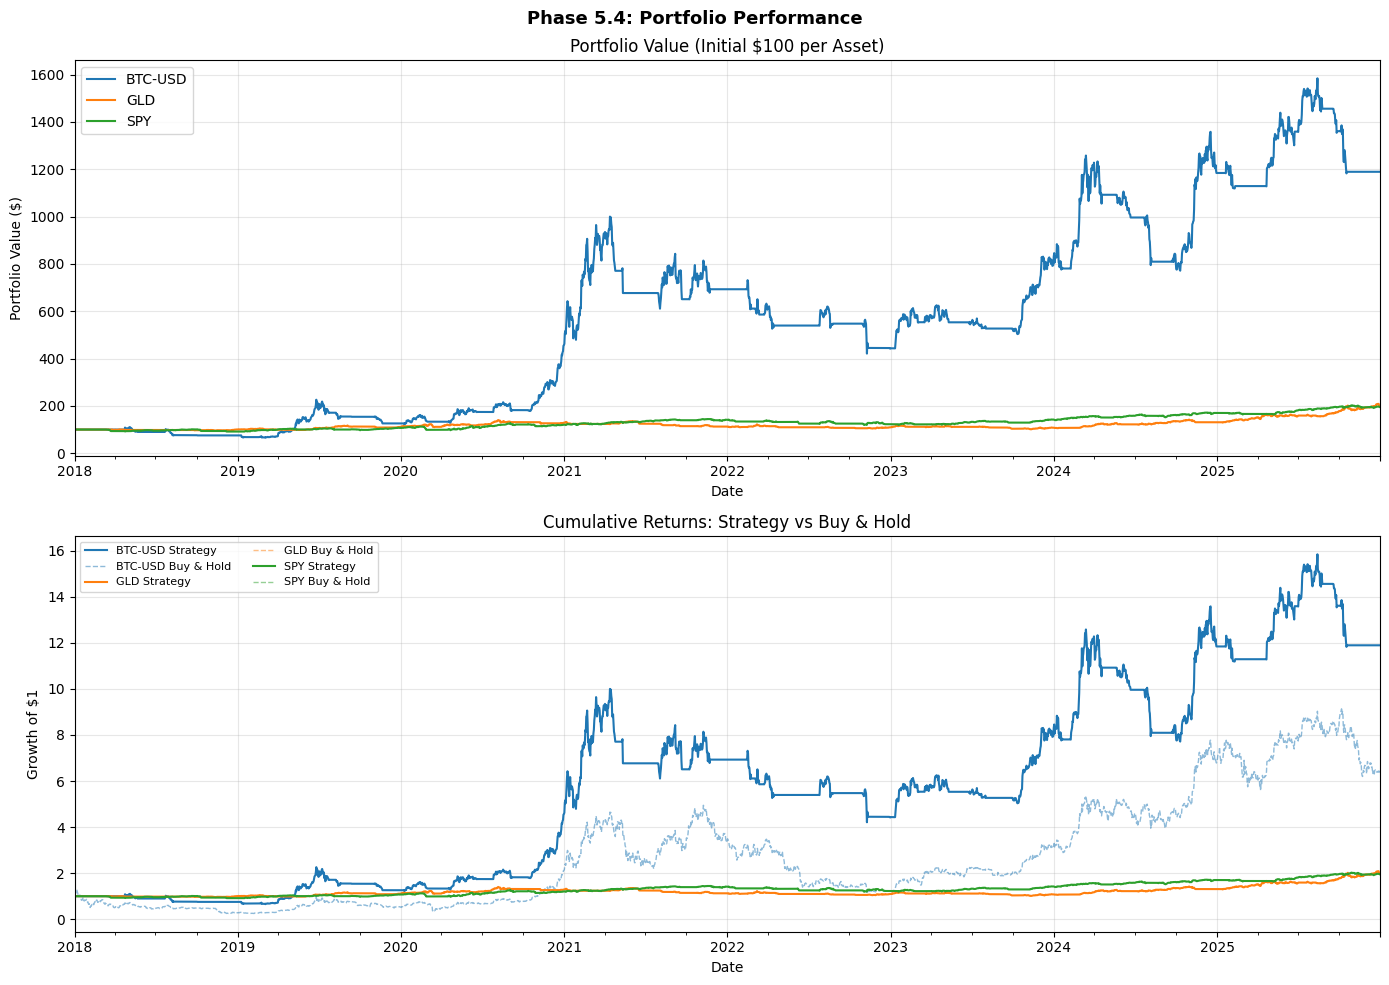


=== Strategy Performance Summary ===
Metric                        BTC-USD         GLD         SPY
-------------------------------------------------------------
Total Return                  1089.5%       98.2%       94.6%
Sharpe Ratio                     0.93        0.75        0.78
Sortino Ratio                    1.44        1.07        1.07
Max Drawdown                   -57.9%      -27.8%      -17.4%
Calmar Ratio                     0.63        0.32        0.50


In [6]:
# =============================================================================
# Equity Curves & Cumulative Return Comparison vs Buy-and-Hold
# =============================================================================
pf_value   = pf.value()    # DataFrame: portfolio $ value per asset
pf_returns = pf.returns()  # DataFrame: daily decimal returns per asset

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Panel 1: Portfolio value
ax1 = axes[0]
for ticker, color in zip(close_prices.columns, ['#1f77b4', '#ff7f0e', '#2ca02c']):
    pf_value[ticker].plot(ax=ax1, label=ticker, color=color, linewidth=1.5)
ax1.set_title('Portfolio Value (Initial $100 per Asset)')
ax1.set_ylabel('Portfolio Value ($)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Panel 2: Cumulative returns — Strategy vs B&H
ax2 = axes[1]
init = close_prices.iloc[0]
for ticker, color in zip(close_prices.columns, ['#1f77b4', '#ff7f0e', '#2ca02c']):
    strat_cum = (1 + pf_returns[ticker].fillna(0)).cumprod()
    bh_cum    = close_prices[ticker] / init[ticker]
    strat_cum.plot(ax=ax2, color=color, linewidth=1.5, label=f'{ticker} Strategy')
    bh_cum.plot(   ax=ax2, color=color, linewidth=1,   linestyle='--', alpha=0.5,
                   label=f'{ticker} Buy & Hold')

ax2.set_title('Cumulative Returns: Strategy vs Buy & Hold')
ax2.set_ylabel('Growth of $1')
ax2.set_xlabel('Date')
ax2.legend(ncol=2, fontsize=8)
ax2.grid(True, alpha=0.3)

fig.suptitle('Phase 5.4: Portfolio Performance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Performance table
print("\n=== Strategy Performance Summary ===")
print(f"{'Metric':<25}", end='')
for t in close_prices.columns:
    print(f"{t:>12}", end='')
print()
print("-" * (25 + 12 * 3))

metrics = {
    'Total Return':  pf.total_return().map('{:.1%}'.format),
    'Sharpe Ratio':  pf.sharpe_ratio().map('{:.2f}'.format),
    'Sortino Ratio': pf.sortino_ratio().map('{:.2f}'.format),
    'Max Drawdown':  pf.max_drawdown().map('{:.1%}'.format),
    'Calmar Ratio':  (pf.annualized_return() / pf.max_drawdown().abs()).map('{:.2f}'.format),
}
for metric_name, values in metrics.items():
    print(f"{metric_name:<25}", end='')
    for t in close_prices.columns:
        print(f"{values[t]:>12}", end='')
    print()


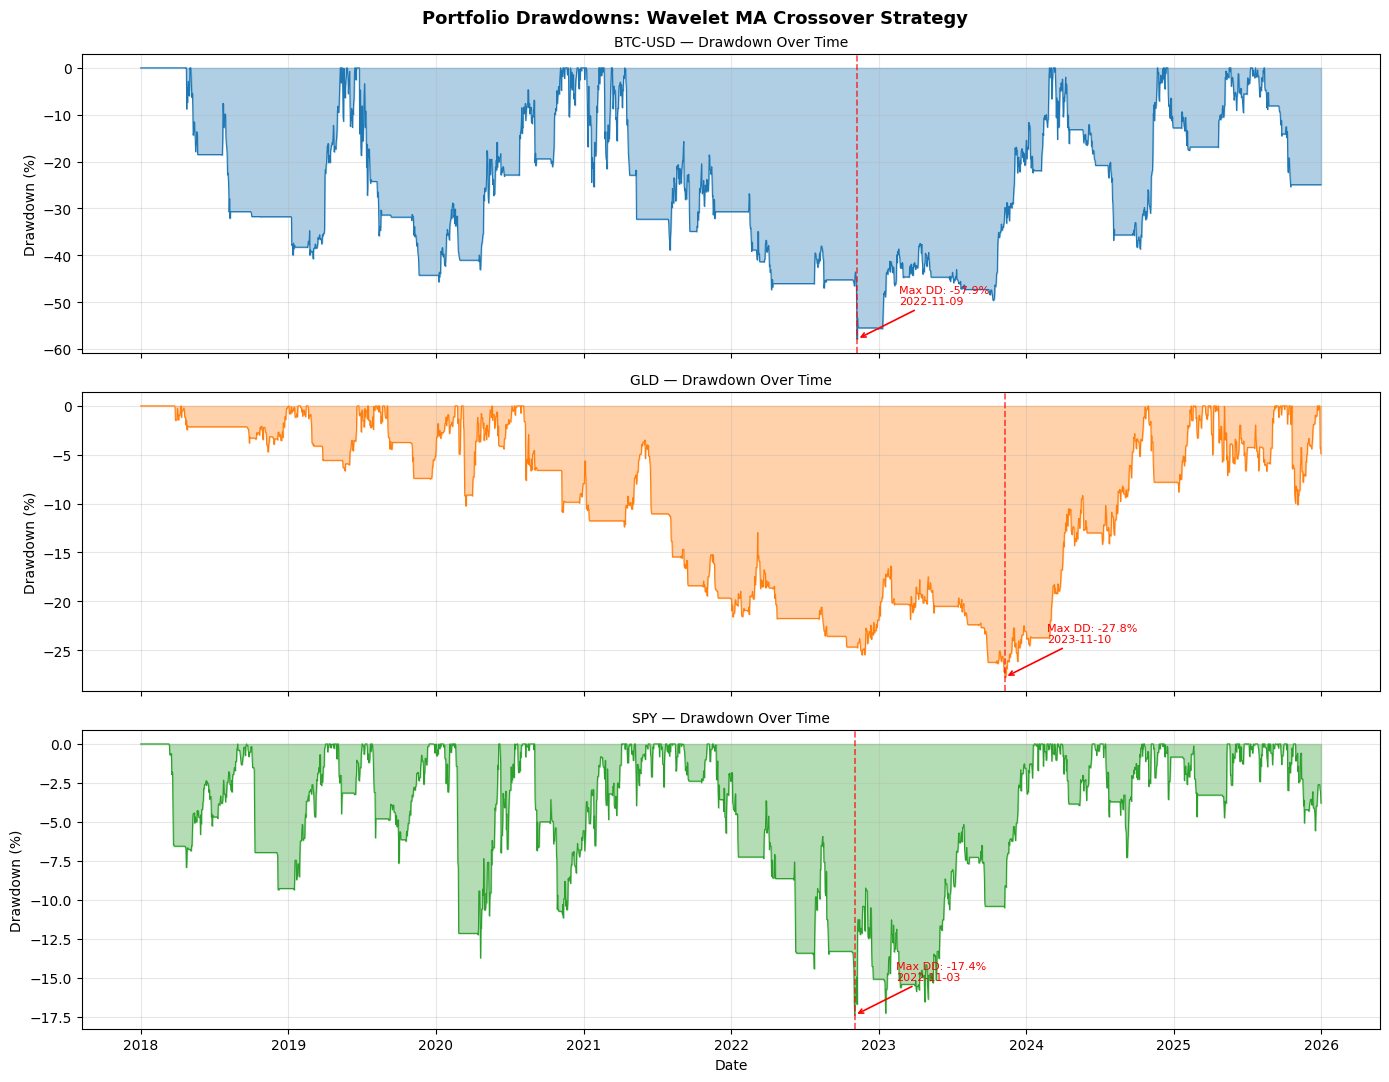

In [7]:
# =============================================================================
# Drawdown Analysis
# =============================================================================
drawdowns = pf.drawdown()  # DataFrame of drawdown % per asset

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

for ax, ticker, color in zip(axes, close_prices.columns, ['#1f77b4', '#ff7f0e', '#2ca02c']):
    dd = drawdowns[ticker] * 100
    ax.fill_between(dd.index, dd.values, 0, color=color, alpha=0.35)
    ax.plot(dd.index, dd.values, color=color, linewidth=0.8)

    max_dd_val  = dd.min()
    max_dd_date = dd.idxmin()
    ax.axvline(max_dd_date, color='red', linewidth=1.2, linestyle='--', alpha=0.7)
    ax.annotate(
        f'Max DD: {max_dd_val:.1f}%\n{max_dd_date.date()}',
        xy=(max_dd_date, max_dd_val),
        xytext=(30, 25), textcoords='offset points',
        fontsize=8, color='red',
        arrowprops=dict(arrowstyle='->', color='red', lw=1.2)
    )
    ax.set_title(f'{ticker} — Drawdown Over Time', fontsize=10)
    ax.set_ylabel('Drawdown (%)')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Date')
fig.suptitle('Portfolio Drawdowns: Wavelet MA Crossover Strategy', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


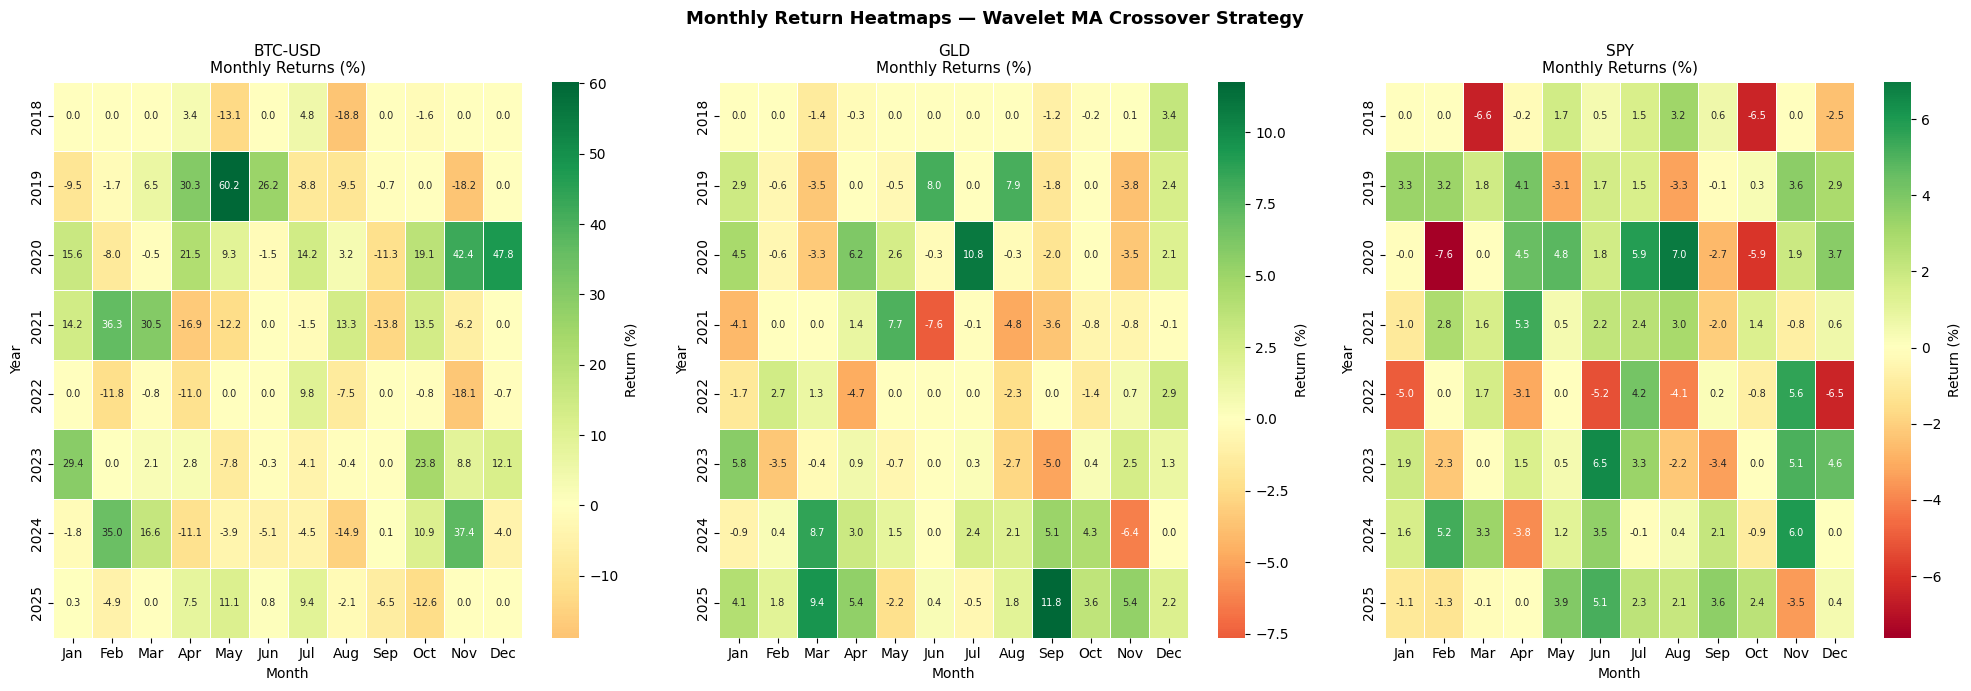

In [8]:
# =============================================================================
# Monthly Return Heatmaps
# =============================================================================
import calendar
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for ax, ticker in zip(axes, close_prices.columns):
    ret_series = pf_returns[ticker].dropna()
    monthly = ret_series.resample('ME').apply(lambda x: (1 + x).prod() - 1) * 100

    pivot = pd.DataFrame({
        'year':   monthly.index.year,
        'month':  monthly.index.month,
        'return': monthly.values,
    }).pivot(index='year', columns='month', values='return')
    pivot.columns = [calendar.month_abbr[m] for m in pivot.columns]

    sns.heatmap(
        pivot, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
        linewidths=0.4, ax=ax, cbar_kws={'label': 'Return (%)'},
        annot_kws={'size': 7}
    )
    ax.set_title(f'{ticker}\nMonthly Returns (%)', fontsize=11)
    ax.set_xlabel('Month')
    ax.set_ylabel('Year')

fig.suptitle('Monthly Return Heatmaps — Wavelet MA Crossover Strategy',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


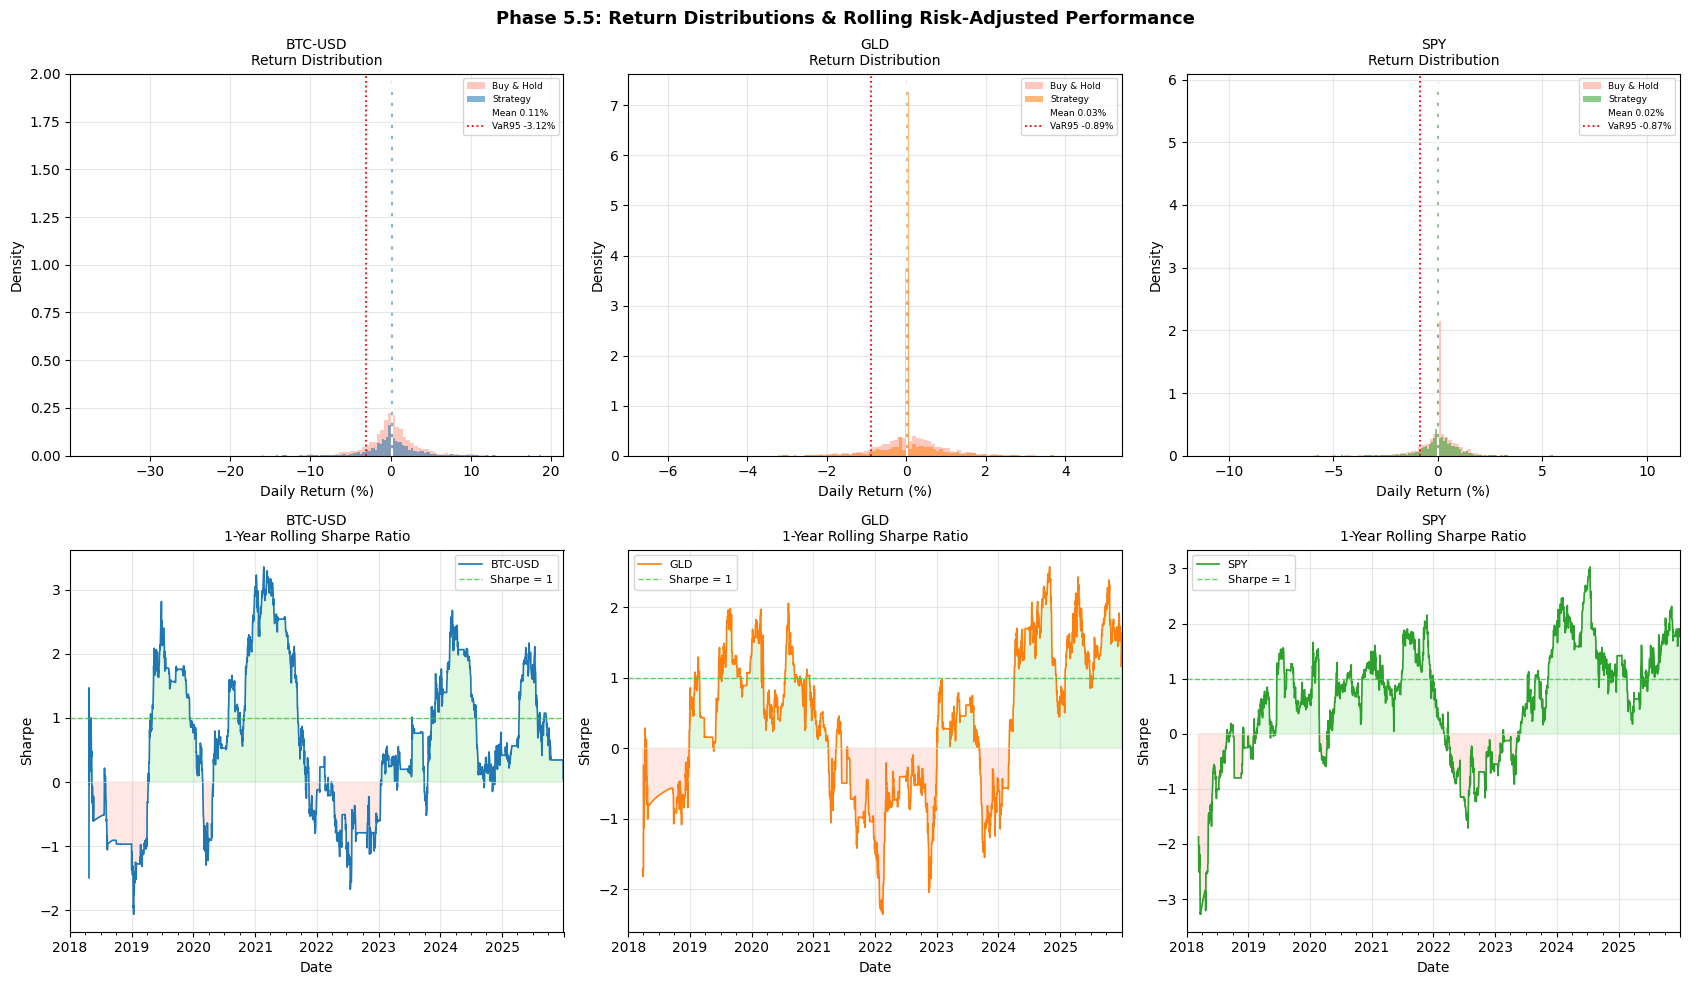


=== Tail Risk Metrics (Strategy Daily Returns) ===
Ticker       VaR(95%)   CVaR(95%)   VaR(99%)   CVaR(99%)     Skew     Kurt
------------------------------------------------------------------------
BTC-USD        -3.12%      -5.40%     -6.61%      -9.27%    0.56   10.87
GLD            -0.89%      -1.70%     -2.02%      -2.96%   -0.69   12.28
SPY            -0.87%      -1.64%     -2.12%      -2.85%   -0.73   12.19


In [9]:
# =============================================================================
# Phase 5.5: Return Distributions & Rolling Sharpe
# =============================================================================
pf_returns = pf.returns()  # DataFrame of daily decimal returns per asset

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for i, (ticker, color) in enumerate(zip(close_prices.columns, ['#1f77b4', '#ff7f0e', '#2ca02c'])):
    strat_ret = pf_returns[ticker].dropna() * 100
    bh_ret    = close_prices[ticker].pct_change().dropna() * 100

    # Row 0 — Return distribution histogram
    ax = axes[0, i]
    ax.hist(bh_ret,    bins=120, alpha=0.35, color='tomato',   density=True, label='Buy & Hold')
    ax.hist(strat_ret, bins=120, alpha=0.55, color=color,      density=True, label='Strategy')
    var95  = np.percentile(strat_ret, 5)
    cvar95 = strat_ret[strat_ret <= var95].mean()
    ax.axvline(strat_ret.mean(), color='white',  linewidth=1.5, linestyle='--',
               label=f'Mean {strat_ret.mean():.2f}%')
    ax.axvline(var95,            color='red',    linewidth=1.3, linestyle=':',
               label=f'VaR95 {var95:.2f}%')
    ax.set_title(f'{ticker}\nReturn Distribution', fontsize=10)
    ax.set_xlabel('Daily Return (%)')
    ax.set_ylabel('Density')
    ax.legend(fontsize=6.5)
    ax.grid(True, alpha=0.3)

    # Row 1 — 1-Year Rolling Sharpe
    ax2 = axes[1, i]
    roll = pf_returns[ticker].rolling(252, min_periods=63)
    rs   = (roll.mean() / roll.std()) * np.sqrt(252)
    rs.plot(ax=ax2, color=color, linewidth=1.2)
    ax2.axhline(0,   color='white',    linewidth=0.8, alpha=0.5)
    ax2.axhline(1.0, color='limegreen', linewidth=1,  linestyle='--', alpha=0.8, label='Sharpe = 1')
    ax2.fill_between(rs.index, rs, 0, where=(rs > 0), alpha=0.15, color='limegreen')
    ax2.fill_between(rs.index, rs, 0, where=(rs < 0), alpha=0.15, color='tomato')
    ax2.set_title(f'{ticker}\n1-Year Rolling Sharpe Ratio', fontsize=10)
    ax2.set_ylabel('Sharpe')
    ax2.set_xlabel('Date')
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)

fig.suptitle('Phase 5.5: Return Distributions & Rolling Risk-Adjusted Performance',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Risk metric table
print("\n=== Tail Risk Metrics (Strategy Daily Returns) ===")
print(f"{'Ticker':<10} {'VaR(95%)':>10} {'CVaR(95%)':>11} {'VaR(99%)':>10} {'CVaR(99%)':>11} {'Skew':>8} {'Kurt':>8}")
print("-" * 72)
for ticker in close_prices.columns:
    r   = pf_returns[ticker].dropna() * 100
    v95 = np.percentile(r, 5)
    c95 = r[r <= v95].mean()
    v99 = np.percentile(r, 1)
    c99 = r[r <= v99].mean()
    print(f"{ticker:<10} {v95:>9.2f}% {c95:>10.2f}% {v99:>9.2f}% {c99:>10.2f}% "
          f"{r.skew():>7.2f} {r.kurtosis():>7.2f}")


## Phase 6: Conclusion and Further Refinements

The Wavelet Transform is an exceptionally powerful tool for algorithmic traders when used correctly to isolate true market structure from microstructure noise. However, several critical caveats must be emphasized:

1. **Lookahead Bias:** You *must* re-calculate the wavelet transform over a rolling or expanding window. Applying it to the entire dataset at once creates "future leak" and will result in spectacularly profitable backtests that immediately fail in live trading.
2. **Wavelet Selection:** We used the simple 'Haar' wavelet due to its alignment with the discrete, jumpy nature of financial data. Other wavelets (like 'Daubechies' `db4` or `db8`) offer smoother approximations but can introduce boundary condition artifacts that distort the most recent (and most important) price data points.
3. **Computational Constraint:** The sliding-window IDWT computation is heavy. In production, this logic should be compiled via Numba, Cython, or executed natively in C++/Rust to handle high-frequency intra-day environments.

By merging Wavelet Denoising with standard technical analysis frameworks, traders can achieve signals that are fundamentally smoother yet geometrically faster to react than classical moving averages, laying the groundwork for highly resilient quantitative portfolios.
